In [1]:
import pandas as pd
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

In [2]:
sampleRate = 1000
duration = 2
t = np.linspace(0, duration, sampleRate * duration, endpoint=False)

In [3]:
sine_wave = np.sin(2 * np.pi * 10 * t)
square_wave = signal.square(2 * np.pi * 5 * t)
num_samples = int(sampleRate * duration)
noise = np.random.normal(0, 1, num_samples)  # mean=0, std=1
composite_wave = sine_wave + noise

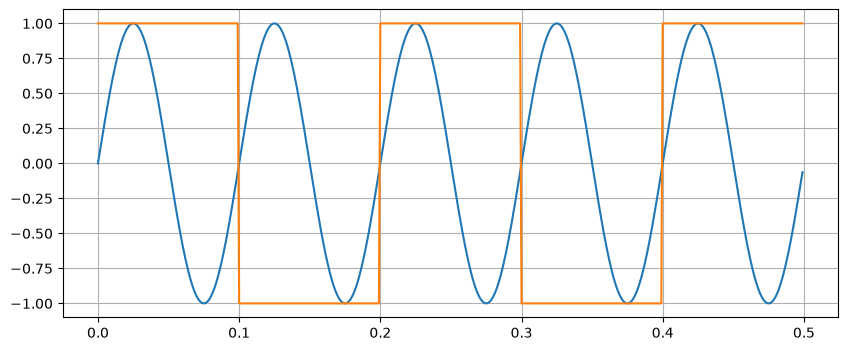

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(t[:500], sine_wave[:500])
plt.plot(t[:500], square_wave[:500])
#plt.plot(t[:500], noise[:500])
plt.grid(True)
plt.show()

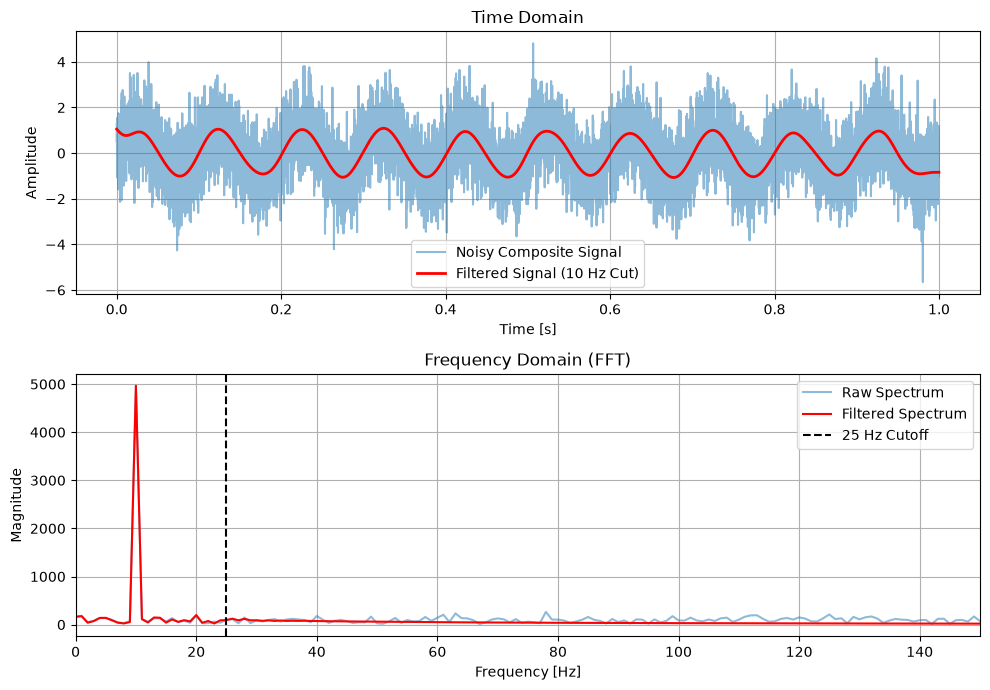

In [13]:
# 2. Design Lowpass Filter
cutoff = 25  # Cutoff frequency in Hz
order = 4
nyquist = 0.5 * sampleRate
normal_cutoff = cutoff / nyquist

# Generate Second-Order Sections (SOS) for stability
sos = signal.butter(order, normal_cutoff, btype='low', output='sos')

# 3. Apply Filter to the Composite Wave
filtered_signal = signal.sosfiltfilt(sos, composite_wave)

# 4. Analyze Frequency Domain (FFT)
freqs = np.fft.rfftfreq(num_samples, 1 / sampleRate)
fft_raw = np.abs(np.fft.rfft(composite_wave))
fft_filtered = np.abs(np.fft.rfft(filtered_signal))

# 5. Plot Time Domain & Frequency Domain
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))

# Plot 1: Time Domain
ax1.plot(t, composite_wave, label='Noisy Composite Signal', alpha=0.5)
ax1.plot(t, filtered_signal, label='Filtered Signal (10 Hz Cut)', color='red', linewidth=2)
ax1.set_title('Time Domain')
ax1.set_xlabel('Time [s]')
ax1.set_ylabel('Amplitude')
ax1.legend()
ax1.grid(True)

# Plot 2: Frequency Domain (FFT)
ax2.plot(freqs, fft_raw, label='Raw Spectrum', alpha=0.5)
ax2.plot(freqs, fft_filtered, label='Filtered Spectrum', color='red', linewidth=1.5)
ax2.axvline(cutoff, color='black', linestyle='--', label='25 Hz Cutoff')
ax2.set_title('Frequency Domain (FFT)')
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Magnitude')
ax2.set_xlim(0, 150)  # Zoom in on relevant frequencies
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()